# Video 13: A four core atlas

Notes for this notebook.

This notebook generates the visuals for the thirteenth video in the Multimodal Spatial Biology series. We apply the same pipeline built across this series, loading, segmentation, quantification, and clustering, to all four tissue cores in this dataset at once, and compare cell composition across genuinely different tissue types, HCC tumor, non tumor liver, tonsil, and hepatocellular adenoma.

This notebook needs harmonypy in addition to the packages used in earlier videos. Install it with pip install harmonypy if you have not already. All output images are saved into outputs/video13.


In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline


In [2]:
from pathlib import Path

OUTPUT_DIR = Path("outputs/video13")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Output folder ready at:", OUTPUT_DIR.resolve())


Output folder ready at: C:\Users\m6sbhatt\Documents\Personal\python_projects\unumlocalia\outputs\video13


## Load and combine all four cores

We reuse the tumor and non tumor liver quantification tables from earlier videos, and quantify the two remaining cores, tonsil and hepatocellular adenoma, the same way, using the same quantify_comet_segmentation function throughout the series.


In [3]:
from unumlocalia.io import DatasetLoader
import time
import warnings
warnings.filterwarnings("ignore", message="invalid value encountered in divide")

DATA_DIR = Path("data/UnumLocalia")

t0 = time.time()
loader = DatasetLoader(str(DATA_DIR)).load(
    do_load_transcripts=True,
    load_boundaries=True,
    load_he=True,
    load_comet=True,
)
print("Load time in seconds:", round(time.time() - t0, 1))

new_core_files = {}
for core_id in ["core03_tonsil", "core04_hca"]:
    df_core = loader.quantify_comet_segmentation(core_id, method_name="cells")
    out_path = OUTPUT_DIR / f"{core_id}_quantification.csv"
    df_core.to_csv(out_path, index=False)
    new_core_files[core_id] = str(out_path)
    print(f"{core_id}: {df_core.shape}, saved to {out_path}")


Load time in seconds: 23.0
core03_tonsil: (25417, 5022), saved to outputs\video13\core03_tonsil_quantification.csv
core04_hca: (6728, 5020), saved to outputs\video13\core04_hca_quantification.csv


In [4]:
core_files = {
    "core01_hcc": "outputs/video3/core01_hcc_quantification.csv",
    "core02_non_tumour": "outputs/video5/core02_non_tumour_quantification.csv",
    "core03_tonsil": new_core_files["core03_tonsil"],
    "core04_hca": new_core_files["core04_hca"],
}

dfs = []
for core_id, path in core_files.items():
    df = pd.read_csv(path)
    df["core"] = core_id
    dfs.append(df)

df_all = pd.concat(dfs, ignore_index=True)
print("Combined table shape:", df_all.shape)
print(df_all["core"].value_counts())


Combined table shape: (46011, 5023)
core
core03_tonsil        25417
core01_hcc            8283
core04_hca            6728
core02_non_tumour     5583
Name: count, dtype: int64


## Removing segmentation artifacts

A small number of segmented cells across this combined table have no detected signal at all, zero for every single marker. This happens when a cell boundary falls in a region with no real image data behind it, typically near a tissue edge or an imaging gap, rather than reflecting a real, unusually quiet cell. We remove these before clustering, the same kind of data cleaning step you would apply to any measurement with an invalid reading.


In [5]:
marker_cols = [c for c in df_all.columns if c.endswith("_mean") and c != "DAPI_mean"]

valid_mask = ~(df_all[marker_cols] == 0).all(axis=1)
print(f"Removing {(~valid_mask).sum()} cells with no detected signal on any marker")

df_all = df_all[valid_mask].reset_index(drop=True)
print("Combined table shape after cleaning:", df_all.shape)


Removing 585 cells with no detected signal on any marker
Combined table shape after cleaning: (45426, 5023)


## Clustering across four cores together

Combining cells from four separate imaging sessions introduces a real risk, technical differences between sessions, staining intensity, exposure, timing, can look like biological differences to a clustering algorithm if left uncorrected. We use Harmony, a standard batch integration method, to adjust for this, so that cells are grouped by genuine marker similarity rather than by which core they happened to come from.


In [6]:
import scanpy as sc
import anndata as ad
from sklearn.preprocessing import StandardScaler

X = StandardScaler().fit_transform(df_all[marker_cols].values)

adata = ad.AnnData(X)
adata.obs["core"] = df_all["core"].values

sc.pp.pca(adata, n_comps=10)
sc.external.pp.harmony_integrate(adata, "core")

sc.pp.neighbors(adata, use_rep="X_pca_harmony", n_neighbors=15)
sc.tl.leiden(adata, resolution=0.3)
df_all["leiden_cluster"] = adata.obs["leiden"].astype(int).values

print(f"Found {df_all['leiden_cluster'].nunique()} clusters across all four cores")


2026-09-15 11:33:31,283 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-09-15 11:33:34,507 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-09-15 11:33:34,737 - harmonypy - INFO - Iteration 1 of 10
2026-09-15 11:33:48,036 - harmonypy - INFO - Iteration 2 of 10
2026-09-15 11:34:01,123 - harmonypy - INFO - Converged after 2 iterations
c:\Users\m6sbhatt\AppData\Local\anaconda3\envs\unumlocalia-env\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\m6sbhatt\AppData\Local\Temp\ipykernel_23156\1012296608.py:14: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(

Found 9 clusters across all four cores


## Composition across tissue types

Let us look at what fraction of each core falls into each cluster, and what defines each cluster.


In [7]:
composition = pd.crosstab(df_all["core"], df_all["leiden_cluster"], normalize="index") * 100
print("Percent of cells per cluster, by core:")
print(composition.round(1))

cluster_profile = df_all.groupby("leiden_cluster")[marker_cols].mean()
cluster_profile_z = ((cluster_profile - cluster_profile.mean()) / cluster_profile.std()).round(2)
print("\nTop 3 defining markers per cluster:")
for cluster_id in cluster_profile_z.index:
    top_markers = cluster_profile_z.loc[cluster_id].sort_values(ascending=False).head(3)
    print(f"Cluster {cluster_id}: {list(top_markers.index)}")


Percent of cells per cluster, by core:
leiden_cluster        0     1     2     3     4     5     6    7    8
core                                                                 
core01_hcc          2.8  32.9  29.2   0.6   6.0   2.3  22.8  3.3  0.1
core02_non_tumour   0.7  43.1  42.6   0.0   2.0   1.3   7.2  3.1  0.0
core03_tonsil      40.3   3.3   0.4  22.4  15.5  14.3   2.1  0.3  1.5
core04_hca          0.6  52.2  25.0   0.0   3.2   2.4  11.6  4.9  0.0

Top 3 defining markers per cluster:
Cluster 0: ['CD45RA - TRITC_mean', 'vimentin - TRITC_mean', 'VEGF - TRITC_mean']
Cluster 1: ['αSMA - TRITC_mean', 'FXIIIa - FITC_mean', 'CD1c - TRITC_mean']
Cluster 2: ['E-Cadherin - TRITC_mean', 'CK8 - TRITC_mean', 'podoplanin - FITC_mean']
Cluster 3: ['CD20 - TRITC_mean', 'CD45RA - TRITC_mean', 'IL-10 - TRITC_mean']
Cluster 4: ['vimentin - TRITC_mean', 'FXIIIa - FITC_mean', 'CD45RA - TRITC_mean']
Cluster 5: ['CD45 - TRITC_mean', 'CD45RA - TRITC_mean', 'vimentin - TRITC_mean']
Cluster 6: ['CK8 - TR

## Reading the atlas

Tonsil serves as a strong positive control here. One cluster, defined by CD20, CD45RA, and IL-10, makes up roughly a fifth of all tonsil cells and is nearly absent everywhere else, tonsil is lymphoid tissue, so a dominant B cell population is exactly what should appear, and it does, found entirely without telling the algorithm what tonsil is.

Several other immune associated clusters are also strongly enriched in tonsil specifically, consistent with lymphoid tissue being broadly immune cell rich. An epithelial cluster, marked by E-Cadherin and CK8, dominates the non tumor liver core and is well represented in the tumor and adenoma cores, essentially absent from tonsil, consistent with hepatocyte identity.

One cluster stands out as a genuine, unplanned finding. It is defined by CK8, E-Cadherin, and CD206, an epithelial marker combination alongside a macrophage marker, and it is far more common in the HCC tumor core than in any other tissue, including the non tumor liver from the same patient population. This may reflect tumor associated macrophages sitting close enough to epithelial cells for their signal to be captured together during segmentation, or a genuine, distinct cell state specific to the tumor microenvironment. Either interpretation would be worth following up with a dedicated analysis, which is beyond what a single video can settle, but finding it at all is a direct product of running the same pipeline across multiple tissue types rather than studying one core in isolation.


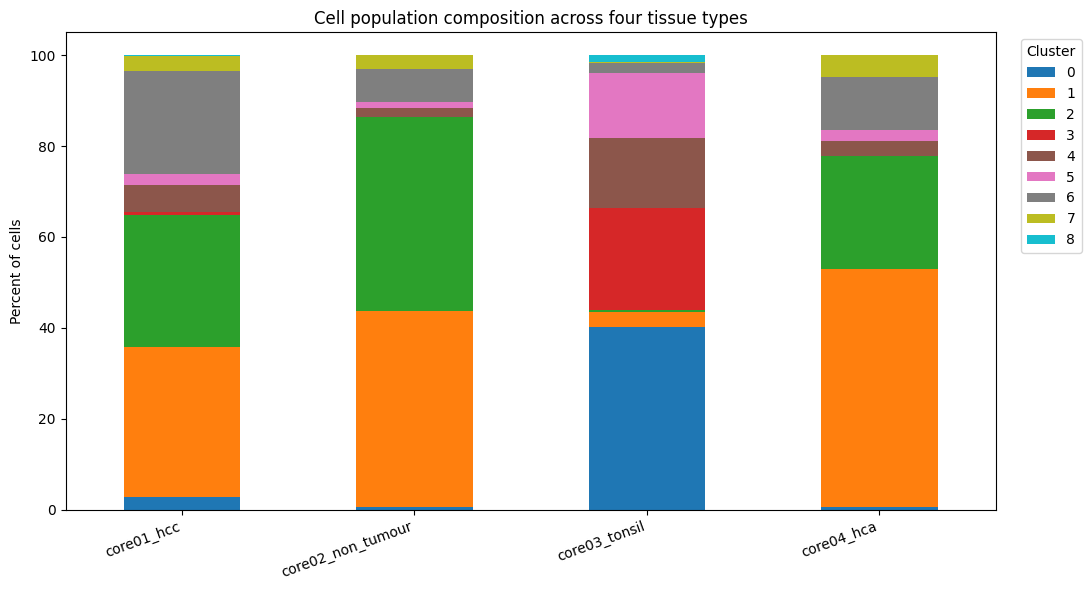

Saved slide_composition_by_core.png


In [13]:
fig, ax = plt.subplots(figsize=(11, 6))
composition.plot(kind="bar", stacked=True, ax=ax, colormap="tab10")
ax.set_ylabel("Percent of cells")
ax.set_xlabel("")
ax.set_title("Cell population composition across four tissue types")
ax.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "slide_composition_by_core.png", dpi=200, facecolor="white")
plt.show()

print("Saved slide_composition_by_core.png")


## Checking how well correction worked

A UMAP projection, colored two ways, by core and by cluster, side by side, gives us a visual check. Where cell states are genuinely shared across tissue types, correction should mix cells from multiple cores within the same cluster. Where a cluster remains dominated by a single core, that is not automatically a failure, it may reflect a real, tissue specific cell state with no equivalent elsewhere, tonsil is organized lymphoid tissue with specialized structures such as germinal centers, which liver tissue simply does not have.


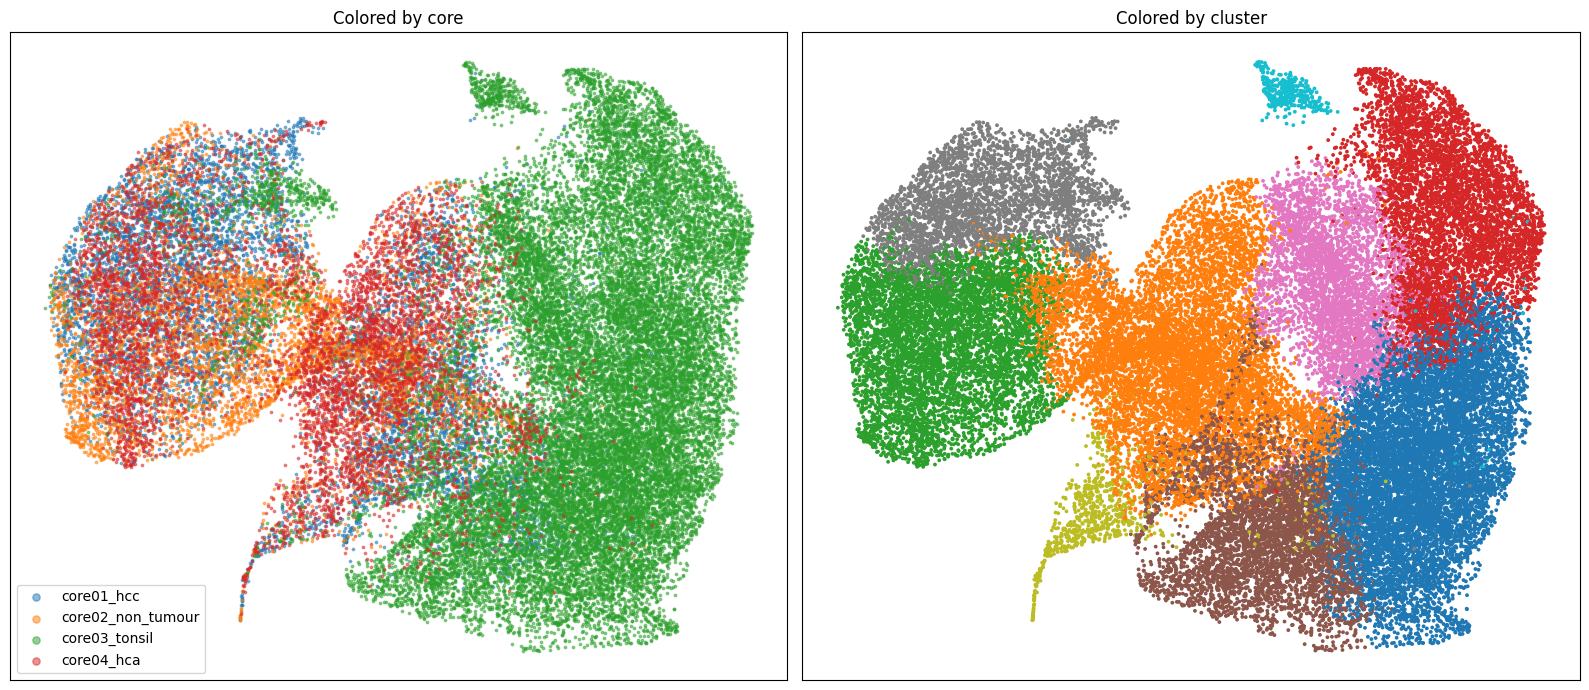

Saved slide_umap_core_vs_cluster.png


In [14]:
sc.tl.umap(adata)
df_all["umap_x"] = adata.obsm["X_umap"][:, 0]
df_all["umap_y"] = adata.obsm["X_umap"][:, 1]

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for core_id, group in df_all.groupby("core"):
    axes[0].scatter(group["umap_x"], group["umap_y"], s=3, alpha=0.5, label=core_id)
axes[0].set_title("Colored by core")
axes[0].legend(markerscale=3)
axes[0].set_xticks([])
axes[0].set_yticks([])

sc1 = axes[1].scatter(df_all["umap_x"], df_all["umap_y"], c=df_all["leiden_cluster"], cmap="tab10", s=3)
axes[1].set_title("Colored by cluster")
axes[1].set_xticks([])
axes[1].set_yticks([])

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "slide_umap_core_vs_cluster.png", dpi=200, facecolor="white")
plt.show()

print("Saved slide_umap_core_vs_cluster.png")


## Summary

Running the same pipeline across all four tissue types in this dataset, rather than one core in isolation, let us validate the entire approach against a strong positive control, tonsil's expected B cell dominance, and surface a genuine, unplanned finding, a tumor enriched population combining epithelial and macrophage markers, that would not have been visible from any single core on its own. The UMAP check also showed real, shared biology mixing correctly across the tumor, non tumor, and adenoma cores, while tonsil retained some of its own distinct territory, consistent with lymphoid tissue containing specialized cell states that liver tissue does not share.

This dataset, openly available under a CC BY 4.0 license from Duchini, Marsh-Wakefield, and colleagues, has carried this entire series, from loading and registration through segmentation, quantification, cross modality validation, unsupervised clustering, spatial statistics, and finally this four core comparison. Real, published, multimodal spatial data, and there was a genuine amount of biology in it to find.
